# 03 — Spiking simulation: does the wiring actually *do* it?

Phase 2 read the wiring: looming detectors (LPLC2, LC4) are the top inputs of the giant fiber, and
DNp04 gets three times the giant fiber's share. Wiring is not behaviour, though. A neuron only
fires if enough input arrives close enough in time, and inhibition can cancel excitation. So this
notebook turns the connectome into **dynamics**: every one of the ~134k neurons becomes a leaky
integrate-and-fire (LIF) neuron, and the signed matrix `W` decides who kicks whom.

Plan:
0. **One neuron** — what the model does, checked against pen-and-paper answers.
1. **(a) Validation** — reproduce Shiu et al. (Nature 2024): sugar taste neurons drive the feeding
   motor neuron MN9. Brian2 reference vs our PyTorch simulator, and our graph vs theirs.
2. **(b) Looming → escape** — drive LPLC2/LC4 at increasing rates: which escape DNs fire, and in
   what order?
3. **(c) Silencing** — remove cell types from `W` to test which pathways are *necessary*.

The heavy runs are cached by `scripts/run_phase3.py`; this notebook loads them (or runs them if
the cache is missing). Simulators: `src/c2c/sim/`, tests: `tests/test_sim.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from c2c.analysis import graph_stats as gs
from c2c.analysis import phase3 as p3
from c2c.analysis import spiking as sp
from c2c.analysis.pathways import input_fractions
from c2c.data import shiu
from c2c.paths import FIGURES
from c2c.sim.network import subnetwork
from c2c.sim.params import SHIU2024 as P
from c2c.sim.torch_lif import simulate_torch

gs.apply_style()
FIGURES.mkdir(parents=True, exist_ok=True)
print(P)
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

LIFParams(v_0=-52.0, v_rst=-52.0, v_th=-45.0, t_mbr=20.0, tau=5.0, t_rfc=2.2, t_dly=1.8, w_syn=0.275, f_poi=250.0, dt=0.1)
torch 2.14.1+cpu | CUDA available: False


## 0. One neuron, by hand

Each neuron has two state variables, both in millivolts:

$$\tau_m \frac{dv}{dt} = v_0 - v + g, \qquad \tau \frac{dg}{dt} = -g$$

`g` is synaptic drive: a presynaptic spike with *c* synapses adds `c × 0.275 mV` to it, 1.8 ms after
the spike. `g` decays in 5 ms and pushes `v`, which leaks back to rest in 20 ms. Above −45 mV the
neuron spikes, resets to −52 mV and is frozen for 2.2 ms. Because the equations are linear between
spikes, each 0.1 ms step is solved **exactly** (no Euler error), see `LIFParams.propagators`.

Below: a 20-synapse input vs the closed-form PSP, and the f–I curve under constant drive vs the
textbook LIF formula $f = 1/(t_{ref} + \tau_m \ln\frac{I}{I-\theta})$.

PSP peak 0.866 mV (closed form 0.1575*c*w_syn = 0.866 mV); max |sim - closed form| = 2.8e-14 mV


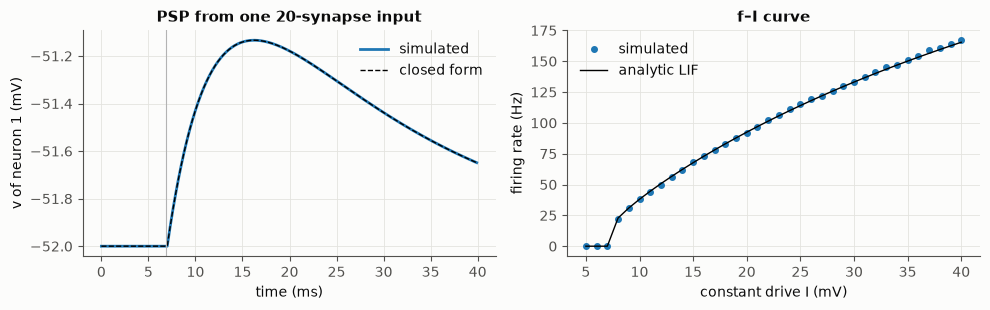

In [2]:
from scipy import sparse

W2 = sparse.csr_matrix(([20.0], ([1], [0])), shape=(2, 2))     # neuron 0 -> neuron 1, 20 synapses
r = simulate_torch(W2, P, forced=([0], [5.0]), t_run=40, record_v=[1], device="cpu",
                   dtype=torch.float64)
t = np.arange(r.v_trace.shape[0]) * P.dt
arrival = 5.0 + P.dt + P.t_dly                       # kick -> spike one step later -> +delay
tt = np.clip(t - arrival - P.dt, 0, None)
analytic = P.v_0 + 20 * P.w_syn * P.tau / (P.tau - P.t_mbr) * (np.exp(-tt / P.tau) - np.exp(-tt / P.t_mbr))

currents = np.linspace(5, 40, 36)
fi = simulate_torch(sparse.csr_matrix((36, 36)), P, i_bias=currents, t_run=1000, device="cpu",
                    dtype=torch.float64)
theta = P.v_th - P.v_0
f_th = np.where(currents > theta,
                1000 / (P.t_rfc + P.t_mbr * np.log(currents / np.maximum(currents - theta, 1e-12))), 0)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(t, r.v_trace[:, 0, 0], lw=2, label="simulated")
ax[0].plot(t, analytic, "k--", lw=1, label="closed form")
ax[0].axvline(arrival, color="0.7", lw=0.8)
ax[0].set(xlabel="time (ms)", ylabel="v of neuron 1 (mV)", title="PSP from one 20-synapse input")
ax[0].legend(frameon=False)
ax[1].plot(currents, fi.rates()[:, 0], "o", ms=4, label="simulated")
ax[1].plot(currents, f_th, "k-", lw=1, label="analytic LIF")
ax[1].set(xlabel="constant drive I (mV)", ylabel="firing rate (Hz)", title="f–I curve")
ax[1].legend(frameon=False)
plt.tight_layout()
print(f"PSP peak {r.v_trace[:, 0, 0].max() - P.v_0:.3f} mV (closed form 0.1575*c*w_syn = "
      f"{0.1575 * 20 * P.w_syn:.3f} mV); max |sim - closed form| = "
      f"{np.abs(r.v_trace[:, 0, 0] - analytic).max():.1e} mV")

One 20-synapse input moves the membrane by under 1 mV, a seventh of the way to threshold. A fly
neuron only fires when many inputs line up: that is the "AND gate" that pure wiring analysis
cannot see.

## 1. (a) Validation: sugar → MN9

Shiu et al. drove 21 sugar-sensing gustatory neurons (GRNs) with Poisson spikes and read out MN9,
the motor neuron that extends the proboscis to feed. Their published output (in their repository)
gives MN9 at **67 Hz for 100 Hz** sugar input and **93 Hz for 200 Hz**, on FlyWire materialization
630. We run four versions of the connectome to separate the effect of each choice:

| variant | edges | signs | modulatory (DA/5-HT/OA) |
|---|---|---|---|
| `ours` | ≥ 5 synapses (2.7 M) | per edge | 0 |
| `ours_mod` | ≥ 5 synapses | per edge | +1 |
| `shiu_min5` | ≥ 5 synapses | per neuron (Dale) | +1 |
| `shiu_full` | all (15.1 M) | per neuron (Dale) | +1 |

In [3]:
nets = {v: p3.network(v) for v in p3.VARIANTS}
pd.DataFrame({v: {"neurons": n.g.n, "edges": n.W.nnz, "synapses": int(abs(n.W).sum()),
                  "sugar GRNs found": len(n.sugar())} for v, n in nets.items()}).T

,neurons,edges,synapses,sugar GRNs found
ours,134181,2653665,33554496,20
ours_mod,134181,2700513,34153566,20
shiu_min5,134181,2700513,34153566,20
shiu_full,138639,15091983,54492922,20


rate_hz       active neurons       
input_hz    100.0 200.0          100.0  200.0
variant                                      
ours         57.0  86.5          389.0  403.0
ours_mod     60.4  82.5          371.0  420.0
shiu_full    62.7  88.8          401.0  435.0
shiu_min5    51.8  84.8          365.0  393.0

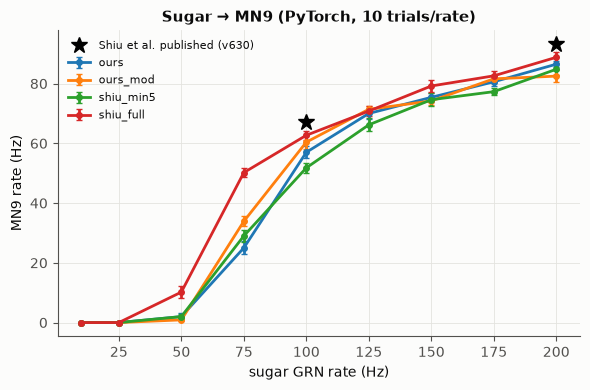

In [4]:
rows, sweeps = [], {}
for v in p3.VARIANTS:
    res, rates = p3.sugar_sweep(v)
    sweeps[v] = (res, rates)
    tab = sp.sweep_table(res, rates, {"MN9": nets[v].mn9()})
    tab["variant"] = v
    tab["active neurons"] = [int((res.rates()[:, rates == r].mean(1) > 0).sum()) for r in tab.input_hz]
    rows.append(tab)
sugar = pd.concat(rows)

fig, ax = plt.subplots(figsize=(6, 4))
for v, d in sugar.groupby("variant", sort=False):
    ax.errorbar(d.input_hz, d.rate_hz, yerr=d.sem_hz, marker="o", ms=4, capsize=2, label=v)
ax.plot(list(shiu.SHIU_REFERENCE_MN9_HZ), list(shiu.SHIU_REFERENCE_MN9_HZ.values()), "k*", ms=12,
        label="Shiu et al. published (v630)")
ax.set(xlabel="sugar GRN rate (Hz)", ylabel="MN9 rate (Hz)", title="Sugar → MN9 (PyTorch, 10 trials/rate)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "phase3_sugar_mn9.png", dpi=150)
sugar[sugar.input_hz.isin([100, 200])].pivot(index="variant", columns="input_hz",
                                             values=["rate_hz", "active neurons"]).round(1)

### Brian2 (reference) vs PyTorch on the whole brain

Same model, two implementations, different random numbers. Spike-by-spike agreement is not
expected (see the next cell), so we compare **per-neuron mean firing rates** across trials.

active_either  active_both  pearson_r  slope_b_vs_a  \
variant   input_hz                                                        
ours      100                 305          295      0.999         1.018   
          200                 352          350      1.000         0.998   
shiu_full 100                 348          342      0.999         1.022   
          200                 392          372      1.000         0.996   

                    median_abs_diff_hz  brian trials  MN9 brian  MN9 torch  \
variant   input_hz                                                           
ours      100                    0.800            10       55.6     58.567   
          200                    0.433            10       86.8     85.867   
shiu_full 100                    0.567            10       61.5     62.400   
          200                    0.433            10       88.4     88.367   

                    |z|>3 (%)  brian s/trial  torch s/trial  
variant   input_hz                                           
ours      100             0.0        111.978          5.065  
          200             0.0        111.978          5.065  
shiu_full 100             0.0        115.600          5.400  
          200             0.0        115.600          5.400

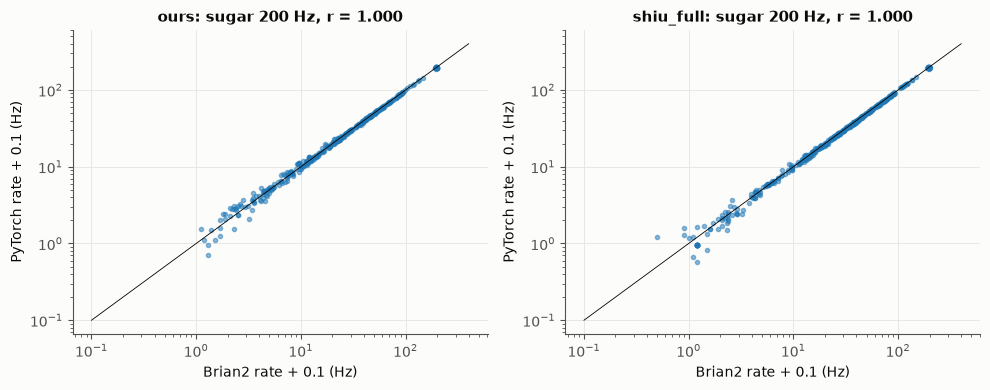

In [5]:
agree = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, v in zip(axes, ["ours", "shiu_full"]):
    rb, tr_b = p3.sugar_reference(v, "brian", n_trials=10)
    rt, tr_t = p3.sugar_reference(v, "torch", n_trials=30)
    for hz in (100, 200):
        mb, mt = rb.rates()[:, tr_b == hz], rt.rates()[:, tr_t == hz]
        stats = sp.rate_agreement(mb.mean(1), mt.mean(1))
        z = sp.z_scores(mb.mean(1), mb.std(1, ddof=1) / np.sqrt(mb.shape[1]),
                        mt.mean(1), mt.std(1, ddof=1) / np.sqrt(mt.shape[1]))
        act = (mb.mean(1) >= 1) | (mt.mean(1) >= 1)
        stats |= {"variant": v, "input_hz": hz, "brian trials": mb.shape[1],
                  "MN9 brian": mb[nets[v].mn9()].mean(), "MN9 torch": mt[nets[v].mn9()].mean(),
                  "|z|>3 (%)": 100 * (abs(z[act]) > 3).mean(),
                  "brian s/trial": float(rb.meta["wall_s"]) / rb.n_trials,
                  "torch s/trial": float(rt.meta["wall_s"]) / rt.n_trials}
        agree.append(stats)
        if hz == 200:
            ax.loglog(mb.mean(1)[act] + 0.1, mt.mean(1)[act] + 0.1, ".", alpha=0.5)
            ax.plot([0.1, 400], [0.1, 400], "k-", lw=0.6)
            ax.set(xlabel="Brian2 rate + 0.1 (Hz)", ylabel="PyTorch rate + 0.1 (Hz)",
                   title=f"{v}: sugar 200 Hz, r = {stats['pearson_r']:.3f}")
plt.tight_layout()
plt.savefig(FIGURES / "phase3_brian_vs_torch.png", dpi=150)
pd.DataFrame(agree).set_index(["variant", "input_hz"]).round(3)

### Why exact spike-by-spike agreement is impossible (and when it isn't)

Three things make two correct simulators disagree spike by spike:

1. **Different random numbers.** Brian2 and PyTorch draw the Poisson input from different
   generators, so the inputs themselves differ. Only the statistics can match.
2. **Floating-point rounding.** PyTorch runs in float32 by default, Brian2 in float64. A neuron
   that ends a step 1e-6 mV above threshold in one and below in the other spikes in only one of
   them. On a GPU, `index_add_` uses atomic adds whose summation order changes from run to run, so
   even PyTorch is not bit-reproducible against itself.
3. **Chaos.** A recurrent network with thousands of neurons amplifies one flipped spike into
   different spike trains everywhere downstream within tens of milliseconds.

Remove all three (identical deterministic input, float64, CPU) and the two simulators agree
**exactly**. The test suite checks this on a random network; here it is on a real piece of the
fly brain: the ~400 neurons that fire when sugar neurons are driven. Then we switch PyTorch to float32 and watch
the trains drift apart.

In [6]:
from c2c.sim.brian_lif import simulate_brian

net = nets["ours"]
keep = p3.local_circuit(net)
Wsub, keep = subnetwork(net.W, keep)
drive = np.flatnonzero(np.isin(keep, net.sugar()))
rng = np.random.default_rng(0)                      # one fixed 200 Hz spike train per GRN
f_idx, f_t = [], []
for i in drive:
    t_spk = np.unique(np.round(np.cumsum(rng.exponential(5.0, 60)), 1))
    t_spk = t_spk[t_spk < 200]
    f_idx += [i] * len(t_spk); f_t += t_spk.tolist()
forced = (np.array(f_idx), np.array(f_t))

kw = dict(forced=forced, t_run=200.0)
rb = simulate_brian(Wsub, P, codegen="numpy", **kw)
r64 = simulate_torch(Wsub, P, device="cpu", dtype=torch.float64, **kw)
r32 = simulate_torch(Wsub, P, device="cpu", dtype=torch.float32, **kw)

def spikes(r):
    return sorted(zip(np.round(r.raster["t"], 4).tolist(), r.raster["neuron"].tolist()))

sb, s64, s32 = spikes(rb), spikes(r64), spikes(r32)
first_diff = next((a[0] for a, b in zip(sb, s32) if a != b), None)
print(f"subcircuit: {Wsub.shape[0]} neurons, {Wsub.nnz} edges, {len(sb)} spikes in 200 ms")
print("Brian2 float64 vs PyTorch float64 identical:", sb == s64)
print("Brian2 float64 vs PyTorch float32 identical:", sb == s32,
      f"| first differing spike at t = {first_diff} ms" if first_diff else "")

subcircuit: 403 neurons, 6364 edges, 2533 spikes in 200 ms
Brian2 float64 vs PyTorch float64 identical: True
Brian2 float64 vs PyTorch float32 identical: False | first differing spike at t = 172.7 ms


In [7]:
rb, rt, keep = p3.subcircuit_comparison()
mb, mt = rb.mean_rate(), rt.mean_rate()
z = sp.z_scores(mb, rb.sem_rate(), mt, rt.sem_rate())
act = (mb >= 1) | (mt >= 1)
print(sp.rate_agreement(mb, mt))
print(f"Poisson input, 30 trials each: {100 * (abs(z[act]) > 3).mean():.1f}% of active neurons "
      f"differ by more than 3 standard errors (about 0.3% expected by chance)")

{'active_either': 354, 'active_both': 350, 'pearson_r': 0.9998192312391933, 'slope_b_vs_a': 1.0065294277992323, 'median_abs_diff_hz': 0.40000000000000036}
Poisson input, 30 trials each: 0.0% of active neurons differ by more than 3 standard errors (about 0.3% expected by chance)


## 2. (b) Looming → escape descending neurons

All 314 LPLC2 and LC4 neurons (both eyes) get Poisson input at 10–200 Hz. Readout: the four
escape DN types from Phase 2, each side, 20 trials of 300 ms per rate. **Latency** = time of the
first spike after stimulus onset; read it with `p_fire` (the share of trials with any spike).

input_hz,10.0,20.0,50.0,100.0,150.0,200.0
neuron,,,,,,
DNp01 L,65.0,44.2,47.6,28.1,34.2,77.7
DNp01 R,41.4,38.4,95.2,131.2,NaN,NaN
DNp02 L,212.9,60.8,13.3,8.6,7.0,5.9
DNp02 R,NaN,154.6,17.6,9.3,7.5,6.1
DNp04 L,17.1,11.1,6.2,5.0,4.5,4.0
DNp04 R,19.4,11.7,7.4,5.5,4.9,4.2
DNp11 L,101.2,44.6,11.8,7.6,6.2,5.5
DNp11 R,165.1,96.3,19.4,9.4,7.9,6.7


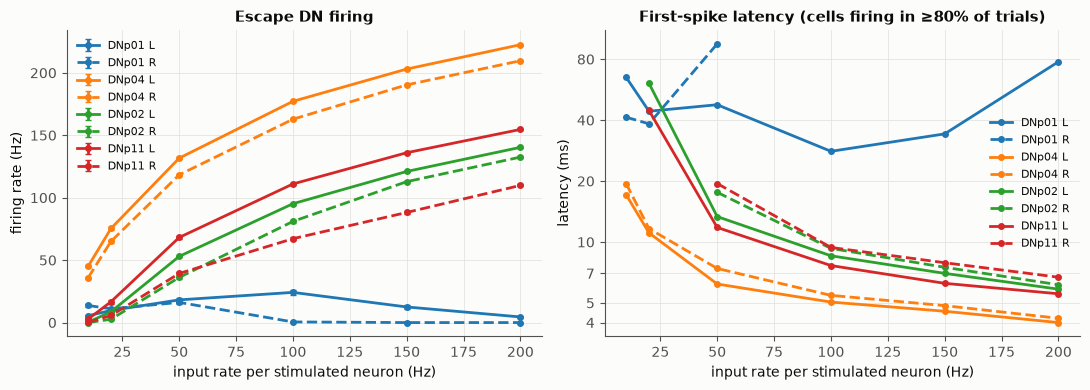

In [8]:
res, rates = p3.looming_sweep("ours")
dns = nets["ours"].escape()
loom = sp.sweep_table(res, rates, dns)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sp.plot_sweep(loom, "rate_hz", ax=ax[0], title="Escape DN firing", ylabel="firing rate (Hz)")
sp.plot_sweep(loom[loom.p_fire >= 0.8], "latency_ms", ax=ax[1], err=None,
              title="First-spike latency (cells firing in ≥80% of trials)", ylabel="latency (ms)")
ax[1].set_yscale("log")
ax[1].set_yticks([4, 5, 7, 10, 20, 40, 80], ["4", "5", "7", "10", "20", "40", "80"])
ax[1].minorticks_off()
plt.tight_layout()
plt.savefig(FIGURES / "phase3_looming_dns.png", dpi=150)
loom.pivot(index="neuron", columns="input_hz", values="latency_ms").round(1)

In [9]:
loom.pivot(index="neuron", columns="input_hz", values="rate_hz").round(0)

input_hz,10.0,20.0,50.0,100.0,150.0,200.0
neuron,,,,,,
DNp01 L,6.0,10.0,18.0,24.0,13.0,4.0
DNp01 R,14.0,11.0,16.0,0.0,0.0,0.0
DNp02 L,0.0,9.0,53.0,95.0,121.0,140.0
DNp02 R,0.0,3.0,36.0,81.0,113.0,133.0
DNp04 L,45.0,75.0,132.0,177.0,203.0,222.0
DNp04 R,36.0,65.0,118.0,163.0,190.0,210.0
DNp11 L,3.0,17.0,68.0,111.0,136.0,155.0
DNp11 R,0.0,6.0,39.0,67.0,88.0,110.0


mean rank at 50 Hz input (1 = first to fire):
DNp04 L    1.20
DNp04 R    1.90
DNp11 L    3.75
DNp02 L    3.85
DNp02 R    5.05
DNp11 R    5.40
DNp01 L    7.15
DNp01 R    7.70


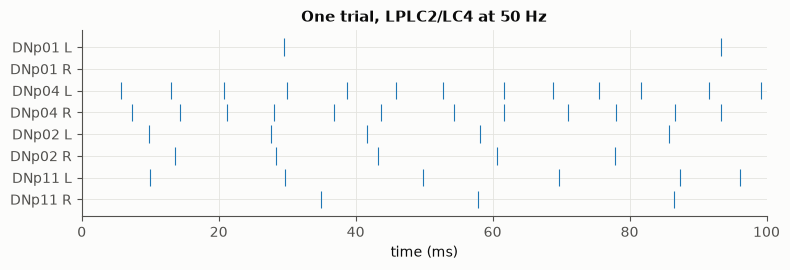

In [10]:
# Firing order in each trial at 50 Hz: rank the eight DNs by first-spike time
cols = rates == 50
fs = res.first_spike[list(dns.values())][:, cols]
order = pd.DataFrame(fs.T, columns=list(dns)).rank(axis=1)
print("mean rank at 50 Hz input (1 = first to fire):")
print(order.mean().sort_values().round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 2.8))
sp.plot_raster(res, dns, trial=int(np.flatnonzero(cols)[0]), ax=ax, t_max=100)
ax.set_title("One trial, LPLC2/LC4 at 50 Hz")
plt.tight_layout()

In [11]:
# Does the order survive on Shiu et al.'s version of the connectome (all synapses, Dale signs)?
res_s, rates_s = p3.looming_sweep("shiu_full")
loom_s = sp.sweep_table(res_s, rates_s, nets["shiu_full"].escape())
pd.concat({"ours": loom.pivot(index="neuron", columns="input_hz", values="latency_ms")[[20, 50, 100]],
           "shiu_full": loom_s.pivot(index="neuron", columns="input_hz", values="latency_ms")[[20, 50, 100]]},
          axis=1).round(1)

ours              shiu_full            
input_hz  20.0  50.0   100.0     20.0  50.0  100.0
neuron                                            
DNp01 L    44.2  47.6   28.1      14.8   8.1   6.2
DNp01 R    38.4  95.2  131.2      11.8   7.7   5.4
DNp02 L    60.8  13.3    8.6      34.9   9.9   7.4
DNp02 R   154.6  17.6    9.3     115.8  13.9   8.0
DNp04 L    11.1   6.2    5.0       9.3   5.9   4.8
DNp04 R    11.7   7.4    5.5      10.3   6.7   5.0
DNp11 L    44.6  11.8    7.6      37.4  10.0   7.2
DNp11 R    96.3  19.4    9.4     176.9  18.4  11.2

## 3. (c) Silencing: which pathways are necessary?

Silencing = set every outgoing synapse of a cell type to zero and re-run (the cells still exist,
nobody hears them). Phase 2's static prediction for each DN is its **input fraction** from each
type. Conditions, at 50 and 100 Hz looming input:

* `-LPLC2`, `-LC4`: one looming channel removed.
* `-relays`: cell types chosen **by rule**: firing ≥ 10 Hz in the intact run and providing ≥ 2% of
  the input to at least one escape DN (LPLC2/LC4 excluded).
* `direct only`: every presynaptic partner of the escape DNs silenced except LPLC2 and LC4, so only
  the direct one-synapse pathway is left.

In [12]:
out, trial_rates, conds, relays = p3.silencing("ours")
print("relay types:", relays)
print({k: len(v) for k, v in conds.items()}, "neurons silenced")

F = input_fractions(nets["ours"].g)
ct = nets["ours"].aligned["cell_type"].to_numpy(dtype=object)
pred = {}
for name, i in dns.items():
    row = F[i]
    s = pd.Series(row.data).groupby(ct[row.indices]).sum()
    pred[name] = {"LPLC2 share": s.get("LPLC2", 0), "LC4 share": s.get("LC4", 0),
                  "relay share": s[s.index.isin(relays)].sum()}
pred = pd.DataFrame(pred).T

sil = {}
for cond, r in out.items():
    for hz in (50, 100):
        sil[(cond, hz)] = r.rates()[list(dns.values())][:, trial_rates == hz].mean(1)
sil = pd.DataFrame(sil, index=list(dns))
table = pd.concat([pred.round(2),
                   sil.xs(100, axis=1, level=1).round(0).add_prefix("Hz @100: "),
                   (sil.xs(50, axis=1, level=1) / sil[("intact", 50)].to_numpy()[:, None]
                    ).round(2).add_prefix("rel @50: ")], axis=1)
table

relay types: ['DNp70', 'LHAD1g1', 'PVLP010', 'PVLP022', 'PVLP122b', 'PVLP130', 'PVLP151']
{'intact': 0, '-LPLC2': 210, '-LC4': 104, '-relays': 18, 'direct only': 750} neurons silenced


,LPLC2 share,LC4 share,relay share,Hz @100: intact,Hz @100: -LPLC2,Hz @100: -LC4,Hz @100: -relays,Hz @100: direct only,rel @50: intact,rel @50: -LPLC2,rel @50: -LC4,rel @50: -relays,rel @50: direct only
DNp01 L,0.08,0.09,0.18,22.0,0.0,51.0,0.0,0.0,1.0,0.00,2.22,0.01,0.00
DNp01 R,0.11,0.09,0.18,1.0,0.0,19.0,0.0,0.0,1.0,0.00,2.30,0.00,0.00
DNp04 L,0.19,0.41,0.03,177.0,158.0,89.0,179.0,183.0,1.0,0.88,0.36,1.04,1.07
DNp04 R,0.23,0.35,0.05,163.0,140.0,87.0,169.0,171.0,1.0,0.83,0.40,1.08,1.10
DNp02 L,0.00,0.20,0.03,94.0,101.0,0.0,108.0,111.0,1.0,1.19,0.00,1.30,1.42
DNp02 R,0.00,0.21,0.04,83.0,93.0,0.0,103.0,109.0,1.0,1.43,0.00,1.78,1.96
DNp11 L,0.00,0.17,0.03,112.0,117.0,0.0,116.0,126.0,1.0,1.11,0.00,1.12,1.32
DNp11 R,0.00,0.12,0.08,68.0,67.0,0.0,76.0,97.0,1.0,0.80,0.00,1.22,1.60


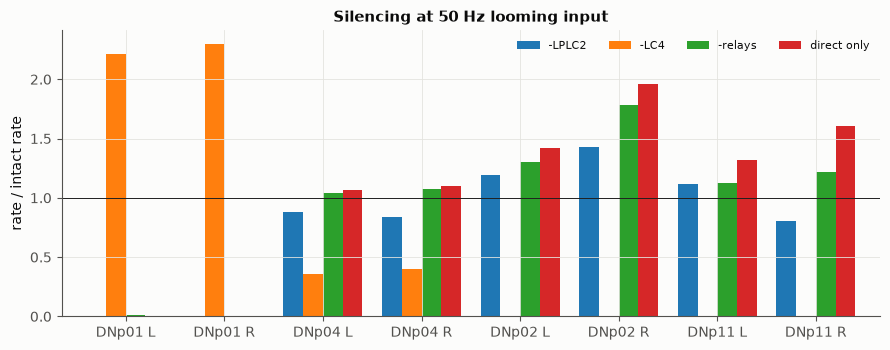

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6))
relative = sil.xs(50, axis=1, level=1).div(sil[("intact", 50)], axis=0)
relative.drop(columns="intact").plot.bar(ax=ax, width=0.8)
ax.axhline(1, color="k", lw=0.6)
ax.set(ylabel="rate / intact rate", title="Silencing at 50 Hz looming input")
ax.legend(frameon=False, fontsize=8, ncol=4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "phase3_silencing.png", dpi=150)

## Takeaways

**(a) The model is reproduced, and the two simulators are the same model.**
- On Shiu et al.'s own input (`shiu_full`), sugar drives MN9 to 62.7 Hz at 100 Hz input and
  88.8 Hz at 200 Hz, against 67.0 and 93.3 Hz in their published output, with 435 vs 448 active
  neurons. The gap fits a newer materialization (783 vs 630) and one sugar neuron that no longer
  exists under its old ID (20 of 21 driven). On our graph MN9 reaches 57.0 and 86.5 Hz.
- Brian2 and PyTorch agree on per-neuron rates across the whole brain (r = 0.999–1.000, slope
  1.00–1.02) and on the 403-neuron sugar circuit (r = 0.9998, no active neuron off by more than
  3 standard errors). With identical deterministic input in float64 they produce the *same spikes
  at the same time steps*; in float32 the first different spike appears at 173 ms.
- For feeding, the ≥5-synapse threshold is the choice that moves the result most: at 75 Hz input
  MN9 fires ~50 Hz on the full graph and ~25–35 Hz on the thresholded variants.

**(b) Looming activates DNp04 first, and the giant fiber hardly at all.** DNp04 fires first and
fastest (mean firing rank 1.20 and 1.90 of 8 at 50 Hz input; 5.0–5.5 ms latency at 100 Hz),
then DNp11 and DNp02 (7.6–9.4 ms). DNp04 is the neuron with three times the giant fiber's
LPLC2/LC4 input share, as Phase 2 predicted. The giant fiber (DNp01) fires at most 24 Hz on our
graph and drops toward 0 as input grows; on Shiu et al.'s graph it fires reliably, second after
DNp04 (5.4–6.2 ms at 100 Hz).

**(c) Silencing shows what the static wiring could not.**
- DNp02 and DNp11 need LC4 completely (silenced → 0 Hz). Without LPLC2, which sends them no
  direct synapses, three of the four fire *more* (+11% to +43% at 50 Hz; DNp11 R is the
  exception, −20%): LPLC2 inhibits them through other neurons.
- DNp04 loses half or more of its firing without LC4 and 12–17% without LPLC2, in line with its
  2:1 input shares.
- The giant fiber's firing roughly *doubles* without LC4, so on our signs LC4's net effect on it
  is inhibitory, although LC4 provides 9% of its input. Without LPLC2 or without the relay types
  (18% of its input) it goes silent.
- For DNp04, DNp02 and DNp11, silencing the relays or every non-looming partner leaves them firing
  as much or more: the direct one-synapse pathway is sufficient.

**Caveats.** No electrical synapses (the real giant fiber circuit uses gap junctions, which an
electron-microscopy connectome cannot see). Signs are predicted from images, and the giant fiber
result shows how much they can matter. There is no adaptation, no neuromodulation and no body.
Phase 4 starts closing that last loop.
